# Figure 3 — Density profiles in a binary Roche potential

This notebook produces **Figure 3** of *Enhanced Mass Transfer from Extended Shock-Supported Stellar Chromospheres*: density versus dimensionless potential for three Roche filling factors. Run all cells in order. The dependencies are NumPy, SciPy, and Matplotlib; no external data files are needed.

The output is `paper_figures/rho_chrom_binary.png` relative to the kernel's working directory.

The donor/accretor mass ratio is $q=M_d/M_a$. Distances with a prime are in units of the separation $a$, potential is in units of $GM_d/a$, and primed speeds are in units of $\sqrt{GM_d/a}$. The helper `potential_rv_dimensionless` returns the positive quantity $\Omega=-\phi'$, so it is negated wherever the physical potential $\phi'$ is used.

The thin and thick solid curves use $f_{\rm con}=0.05$ and $0.1$, respectively. The dashed curves use $f_{\rm con}=10^{-11}$ to approach the thermal limit without dividing by zero.


In [5]:
from pathlib import Path

import numpy as np
from scipy.optimize import brentq
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Physical constants in CGS; user-facing masses, radii, and periods use solar units/days.
G = 6.6743e-8         # cm^3 g^-1 s^-2
Msun = 1.98847e33    # g
Rsun = 6.957e10      # cm
day = 86400.0       # s

OUTPUT_DIR = Path("./paper_figures")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

mpl.rcParams.update({
    "text.usetex": False,
    "axes.formatter.use_mathtext": True,
    "font.family": "STIXGeneral",
    "mathtext.fontset": "cm",
    "axes.unicode_minus": False,
    "axes.linewidth": 1.5,
})

## Orbital geometry and potential

The volume-radius potential uses an expansion through $(r_V/a)^6$ inside the gravitational term. The Roche radius is the donor's volume-equivalent Eggleton radius; it is distinct from the distance to $L_1$.


In [2]:
def semi_major_axis(P_days, Md_Msun, Ma_Msun):
    """Return separation in solar radii from Kepler's law for a circular binary."""
    period = P_days * day
    donor_mass = Md_Msun * Msun
    accretor_mass = Ma_Msun * Msun
    a_cubed = G * (donor_mass + accretor_mass) * (period / (2 * np.pi))**2
    return a_cubed**(1 / 3) / Rsun


def roche_lobe_radius(q, a_Rsun):
    """Donor volume-equivalent Roche radius; q = Md/Ma, output units match a_Rsun."""
    q23 = q**(2 / 3)
    q13 = q**(1 / 3)
    return 0.49 * q23 / (0.6 * q23 + np.log(1 + q13)) * a_Rsun


def potential_rv_dimensionless(rv_a, q_input):
    """Return positive Omega = -phi' at volume radius rv_a = r_V/a.

    q_input is Md/Ma; the reciprocal below is Ma/Md. The potential
    normalization is GMd/a, so the result has no physical units.
    """
    q = 1.0 / q_input
    onebq = 1.0 / q
    a1 = (1 / 3) * (1.0 + q)
    a2 = (4 / 45) * ((1.0 + q)**2 + 9 * q**2 + 3 * q * (1.0 + q))
    term_const = q + q / (2.0 * (1.0 + onebq))
    term_r = 1.0 / rv_a + a1 * rv_a**2 + a2 * rv_a**5
    return term_const + term_r


def roche_potential(x, y, z, q_input):
    """Positive Omega = -phi' with donor at x=0 and accretor at x=1.

    Coordinates are in units of a; q_input = Md/Ma. Rotation is about
    the binary center of mass and the orbit lies in the x-y plane.
    """
    q = 1.0 / q_input
    x_cm = q / (1.0 + q)
    r1 = np.sqrt(x**2 + y**2 + z**2)
    r2 = np.sqrt((x - 1.0)**2 + y**2 + z**2)
    cylindrical_radius2 = (x - x_cm)**2 + y**2
    return 1.0 / r1 + q / r2 + 0.5 * (1.0 + q) * cylindrical_radius2


def find_L1(q_input, tol=1e-10):
    """Find dOmega/dx = 0 between the stars; return x_L1/a for q_input=Md/Ma."""
    q = 1.0 / q_input
    x_cm = q / (1.0 + q)

    def derivative(x):
        r1, r2 = abs(x), abs(x - 1.0)
        return -x / r1**3 - q * (x - 1.0) / r2**3 + (1.0 + q) * (x - x_cm)

    return brentq(derivative, 1e-6, 1.0 - 1e-6, xtol=tol)


def find_L2(q_input, tol=1e-10):
    """Find dOmega/dx = 0 beyond the accretor; return x_L2/a for q_input=Md/Ma."""
    q = 1.0 / q_input
    x_cm = q / (1.0 + q)

    def derivative(x):
        r1, r2 = abs(x), abs(x - 1.0)
        return -x / r1**3 - q * (x - 1.0) / r2**3 + (1.0 + q) * (x - x_cm)

    return brentq(derivative, 1.0 + 1e-6, 5.0, xtol=tol)

## Average over the shock-speed distribution

At each potential, the code maps back to a volume radius by finding the nearest point on a 1,000-point radius grid, then uses midpoint quadrature over a half-normal shock-speed distribution. The integration extends from zero to $10v'_{\rm con}$; the Gaussian weight is not renormalized after this truncation.

The prefactor includes the sonic normalization $e^{-1/2}$. The resulting density at the photosphere is approximately $\rho_{\rm ph}/\sqrt e$.


In [3]:
def mean_chromosphere_density(q, rd_by_rl, vT_prime, vconv_prime,
                             phi_prime, rho_ph=1e-9, vs_res=1000):
    """Return the shock-averaged density at the physical potential phi'.

    q = Md/Ma; rd_by_rl = Rd/RL. Both speeds are scaled by sqrt(GMd/a),
    not by the stellar escape speed. rho_ph sets the returned density units.
    The requested figure uses rho_ph=1, giving rho/rho_ph directly.
    vs_res counts bin edges (there are vs_res-1 midpoint samples).
    """
    r_L1_prime = roche_lobe_radius(q, 1.0)  # Volume Roche radius, not x_L1.
    Rd_prime = rd_by_rl * r_L1_prime

    # Invert the potential by locating the nearest point on a 1,000-point radius grid.
    radius_grid = np.linspace(Rd_prime, 2.0 * r_L1_prime, 1000)
    radius_potentials = -potential_rv_dimensionless(radius_grid, q)
    phi_phot = -potential_rv_dimensionless(Rd_prime, q)
    rphi = radius_grid[np.argmin(np.abs(radius_potentials - phi_prime))]

    # Avoid the singular density of the half-normal distribution at vconv'=0.
    # The thermal comparison uses a very small positive vconv' instead.
    shock_edges = np.linspace(
        0, 10 * vconv_prime, vs_res
    )
    shock_midpoints = (shock_edges[1:] + shock_edges[:-1]) / 2.0
    shock_speed2 = shock_midpoints**2
    total_speed2 = shock_speed2 + vT_prime**2

    gaussian_weight = np.exp(-shock_speed2 / (2 * vconv_prime**2))
    potential_factor = np.exp(-(phi_prime - phi_phot) / total_speed2)
    area_exponent = shock_speed2 / total_speed2
    dilution_factor = (Rd_prime / rphi)**(2 * area_exponent)

    integral = np.sum(
        gaussian_weight * np.diff(shock_edges) * dilution_factor * potential_factor
    )
    # Half-normal PDF normalization times the e^(-1/2) sonic factor.
    return (1.0 / np.sqrt(np.exp(1))) * (1.0 / vconv_prime) * np.sqrt(2.0 / np.pi) * rho_ph * integral

## Paper parameters and Figure 3

The circular binary has $M_d=1\,M_\odot$, $M_a=0.5\,M_\odot$, and $P=1000$ days. Colors indicate $f_{\rm RL}=0.65,0.8,0.99$. All profiles use $f_T=c_T/v_{\rm esc}=0.1$; $f_{\rm con}=v_{\rm con}/v_{\rm esc}$ is $10^{-11},0.05,0.1$ for dashed, thin-solid, and thick-solid lines. The potential step is $0.005$ and shock quadrature uses 1,000 bin edges. The shaded region extends from the physical $L_1$ potential to the physical $L_2$ potential.


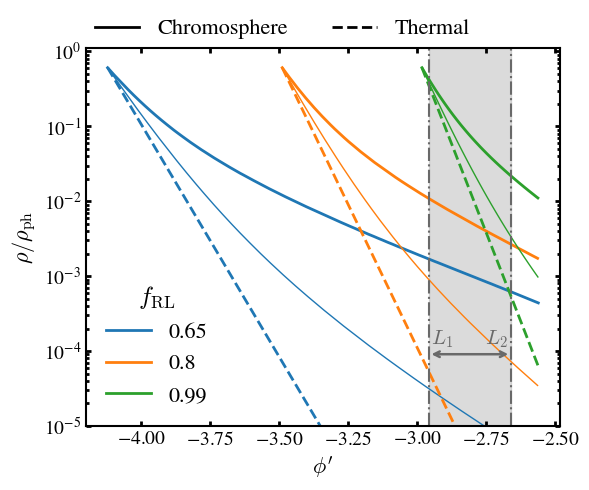

In [4]:
P = 1000.0
Md = 1.0
Ma = 0.5
q = Md / Ma
rd_by_rls = [0.65, 0.8, 0.99]

xl1 = find_L1(q)
xl2 = find_L2(q)
phi_l2 = -roche_potential(xl2, 0, 0, q_input=q)

# Physical (negative) L1 potential in units of GMd/a.
l1_pot = -roche_potential(xl1, y=0, z=0, q_input=q)

r_L1_prime = roche_lobe_radius(q, 1.0)

phi_grid_interval = 0.005

# A tiny positive shock width provides the thermal limit without division by zero.
fcon_grid = [1e-11, 0.05, 0.1]

sma = semi_major_axis(P, Md, Ma)
# Potential scale in (km/s)^2; its square root converts km/s to primed speeds.
pot_fact_km2s2 = (G * Md * Msun / (sma * Rsun)) / 1e10

# Dashed: near-thermal limit; thin/thick solids: fcon=0.05/0.1.
linestyles = ['--', '-', '-']
linewidths = [2, 1, 2]
cols = ['C0', 'C1', 'C2']

fig, ax = plt.subplots(figsize=(6, 5))

for rd_by_rl, col in zip(rd_by_rls, cols):

    Rd_prime = rd_by_rl * r_L1_prime
    Rd = Rd_prime * sma

    vesc = np.sqrt(2.0 * G * Md * Msun / (Rd * Rsun)) / 1e5

    phi_phot = -potential_rv_dimensionless(Rd_prime, q)

    phi_grid = np.arange(phi_phot, phi_l2+0.1, phi_grid_interval)

    for fcon, linestyle, lw in zip(fcon_grid, linestyles, linewidths):

        chrom_dens_phi_arr = []

        vconv_prime = fcon * vesc / np.sqrt(pot_fact_km2s2)
        vT_prime = 0.1 * vesc / np.sqrt(pot_fact_km2s2)

        for phi_prime in phi_grid:

            chrom_dens = mean_chromosphere_density(
                q=q,
                rd_by_rl=rd_by_rl,
                vT_prime=vT_prime,
                vconv_prime=vconv_prime,
                phi_prime=phi_prime,
                rho_ph=1.0,
                vs_res=1000
            )

            chrom_dens_phi_arr.append(chrom_dens)

        ax.plot(
            phi_grid,
            chrom_dens_phi_arr,
            c=col,
            linestyle=linestyle,
            linewidth=lw
        )

ax.set_yscale('log')
ax.axvline(l1_pot, c='dimgrey', linestyle='-.', linewidth=1.5)
ax.axvline(phi_l2, c='dimgrey', linestyle='-.', linewidth=1.5)

# Shade the potential interval between L1 and L2.
ax.axvspan(l1_pot, phi_l2, color='gray', alpha=0.28)

# Double-headed arrow marking the L1-L2 region
xtrans = ax.get_xaxis_transform()  # x in data coords, y in axes fraction

ax.annotate(
    '',
    xy=(phi_l2, 0.19),
    xytext=(l1_pot, 0.19),
    xycoords=xtrans,
    textcoords=xtrans,
    arrowprops=dict(
        arrowstyle='<->',
        color='dimgrey',
        lw=1.8
    )
)

ax.text(
    l1_pot+0.01,
    0.2,
    r'$L_1$',
    transform=xtrans,
    ha='left',
    va='bottom',
    color='dimgrey',
    fontsize=15
)

ax.text(
    phi_l2-0.01,
    0.2,
    r'$L_2$',
    transform=xtrans,
    ha='right',
    va='bottom',
    color='dimgrey',
    fontsize=15
)

ax.set_ylim(1e-5, 1.1)

# Bottom-left color legend
color_handles = [
    Line2D([0], [0], color=col, lw=2, linestyle='-', label=f'{rd_by_rl:g}')
    for rd_by_rl, col in zip(rd_by_rls, cols)
]

leg_colors = ax.legend(
    handles=color_handles,
    title=r'$f_{\rm RL}$',
    loc='lower left',
    frameon=False,
    fontsize=16,
    title_fontsize=18
)

ax.add_artist(leg_colors)

# Top linestyle legend
style_handles = [
    Line2D([0], [0], color='k', lw=2, linestyle='-', label='Chromosphere'),
    Line2D([0], [0], color='k', lw=2, linestyle='--', label='Thermal')
]

ax.legend(
    handles=style_handles,
    loc=(0,1),
    frameon=False,
    fontsize=16,
    ncol=2
)

ax.tick_params(
    which='both',
    direction='in',
    top=True,
    right=True,
    labelsize=14,
    labelbottom=True,
    width=2
)

ax.set_ylabel(r'$\rho/\rho_{\rm ph}$', fontsize=16)
ax.set_xlabel(r"$\phi'$", fontsize=16)

plt.tight_layout()

fig.savefig(OUTPUT_DIR / 'rho_chrom_binary.png', dpi=200, bbox_inches='tight')

plt.show()